# 🧠 Solución Maestra: Análisis Multidimensional y Clusterización

Este notebook contiene la solución de referencia para los 5 equipos. Aplicaremos distintos algoritmos de la librería `scikit-learn` a 3 escenarios de telemetría de jugadores.

### Los 3 Escenarios:
1. **Economía del Juego (Blobs):** Horas Jugadas vs Gasto (3 grupos esféricos).
2. **Detección de Hackers (Lunas):** KDA Ratio vs % Headshots (2 grupos entrelazados).
3. **Estilos de Batalla (Círculos):** Distancia vs Loot (2 grupos concéntricos).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Algoritmos
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, SpectralClustering
from sklearn.mixture import GaussianMixture

# Configuración visual
sns.set_theme(style="whitegrid")

# 1. Cargar Datos
df = pd.read_csv('datasets/comportamiento_jugadores.csv')

# 2. Función Helper para graficar los 3 escenarios
def evaluar_algoritmo(nombre_algoritmo, modelo_configurador):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Rendimiento de {nombre_algoritmo}', fontsize=16, fontweight='bold')
    
    escenarios = df['Escenario'].unique()
    clusters_esperados = [3, 2, 2] # Blobs(3), Lunas(2), Anillos(2)
    
    for i, (escenario, k_esperado) in enumerate(zip(escenarios, clusters_esperados)):
        # Filtrar datos
        df_esc = df[df['Escenario'] == escenario].copy()
        X = df_esc[['Metrica_X', 'Metrica_Y']].values
        
        # ESCALADO DE DATOS (Vital para distancias)
        X_scaled = StandardScaler().fit_transform(X)
        
        # Instanciar y Entrenar
        modelo = modelo_configurador(k_esperado, escenario)
        if hasattr(modelo, 'fit_predict'):
            labels = modelo.fit_predict(X_scaled)
        else:
            modelo.fit(X_scaled)
            labels = modelo.predict(X_scaled)
            
        # Graficar
        sns.scatterplot(x=X[:,0], y=X[:,1], hue=labels, palette='tab10', ax=axes[i], legend=False)
        axes[i].set_title(escenario.replace('_', ' '))
        axes[i].set_xlabel(df_esc['Descripcion_Ejes'].iloc[0].split(' | ')[0])
        axes[i].set_ylabel(df_esc['Descripcion_Ejes'].iloc[0].split(' | ')[1])
        
    plt.tight_layout()
    plt.show()

In [8]:
df["Descripcion_Ejes"].unique()

<StringArray>
[              'X: Horas_Semana | Y: Gasto_USD',
       'X: KDA_Ratio | Y: Porcentaje_Headshots',
 'X: Distancia_Metros | Y: Cajas_Loot_Abiertas']
Length: 3, dtype: str

--- 
## 🛑 Equipo 1: K-Means (Basado en Centroides)
**Lógica Teórica:**
Coloca *K* centroides al azar, asigna cada punto al más cercano (distancia Euclidiana) y recalcula el centro promediando los puntos. Repite hasta que no haya cambios.

**Predicción de Rendimiento:**
*   **Escenario 1 (Economía):** Perfecto. Asume que los grupos son convexos y esféricos.
*   **Escenario 2 (Hackers/Lunas):** Fracaso total. Cortará las lunas a la mitad porque solo traza líneas rectas de distancia, ignorando la continuidad de la forma.
*   **Escenario 3 (Estilos/Anillos):** Fracaso total. No entiende el concepto de "contener" o rodear a otro clúster.

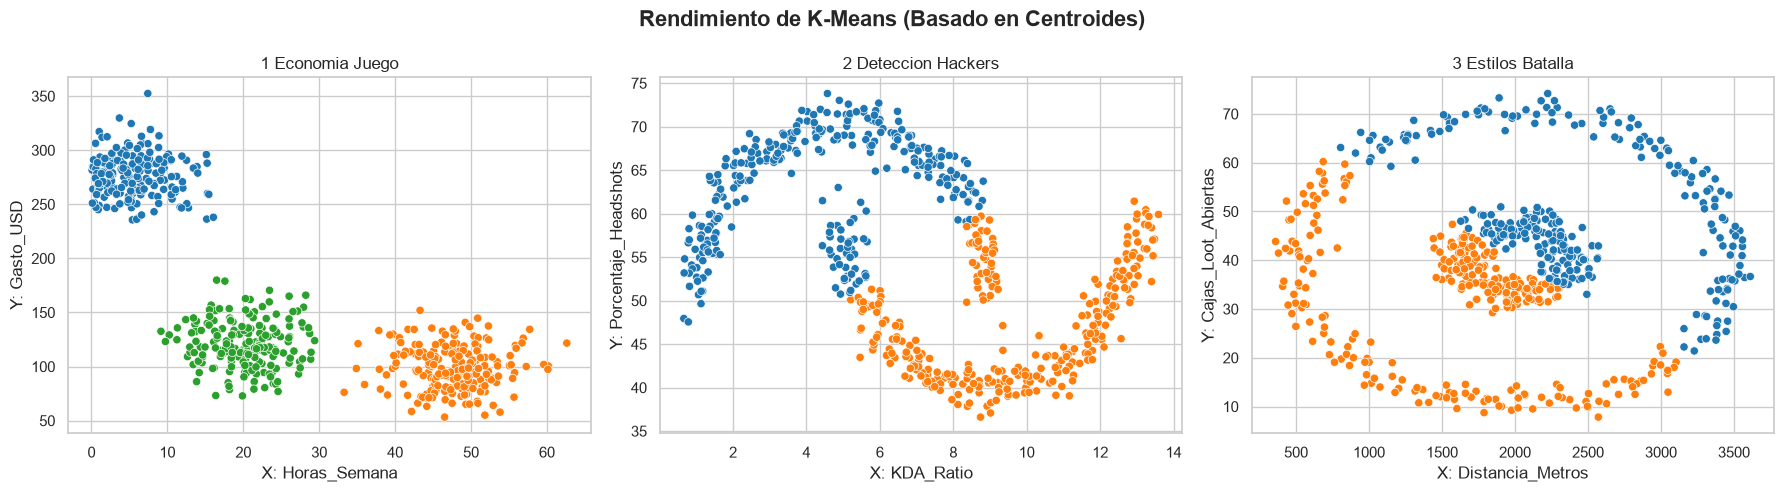

In [3]:
def config_kmeans(k, esc):
    return KMeans(n_clusters=k, random_state=42, n_init=10)

evaluar_algoritmo("K-Means (Basado en Centroides)", config_kmeans)

--- 
## 🛑 Equipo 2: DBSCAN (Basado en Densidad)
**Lógica Teórica:**
Busca zonas con muchos puntos juntos (definido por el radio `eps` y puntos mínimos `min_samples`). Si un punto está en el vacío, se etiqueta como anomalía/ruido (-1). No necesita conocer el número de clústeres (*K*).

**Predicción de Rendimiento:**
*   **Todos los escenarios:** Brillará siempre que los parámetros sean correctos. Es perfecto para las Lunas y los Anillos porque sigue la ruta de los puntos sin importar la forma.

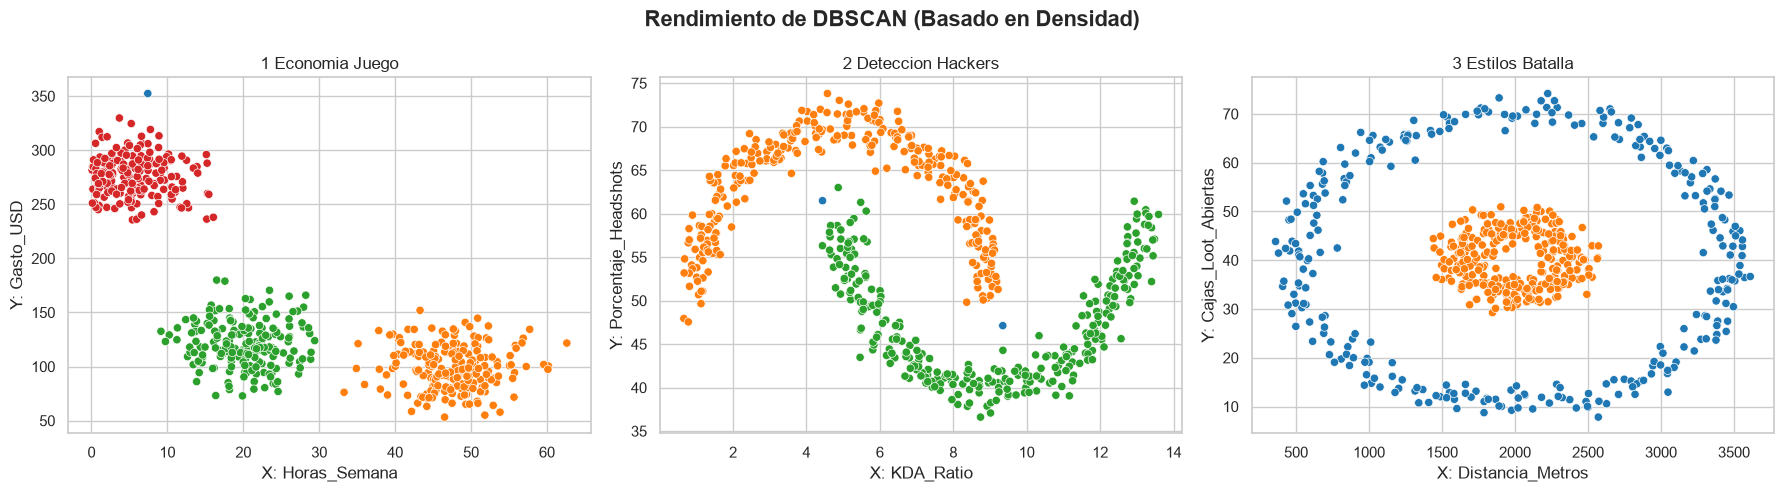

In [9]:
def config_dbscan(k, esc):
    # Los hiperparámetros de DBSCAN son sensibles al escenario incluso estando escalados.
    if 'Economia' in esc:
        return DBSCAN(eps=0.3, min_samples=10)
    else:
        return DBSCAN(eps=0.25, min_samples=5)

evaluar_algoritmo("DBSCAN (Basado en Densidad)", config_dbscan)

--- 
## 🛑 Equipo 3: Agglomerative Clustering (Jerárquico)
**Lógica Teórica:**
Enfoque "Bottom-Up" (De abajo hacia arriba). Al inicio, cada punto es su propio grupo. Se calculan todas las distancias y se unen los dos más cercanos. Esto se repite hasta tener *K* grupos. La forma de medir la distancia entre grupos se llama `linkage` (ej. 'ward' minimiza la varianza, 'single' minimiza la distancia más corta).

**Predicción de Rendimiento:**
*   Con linkage 'ward' (por defecto), se comportará muy parecido a K-Means, fallando en anillos y lunas.
*   Con linkage 'single', puede resolver lunas y anillos porque une los vecinos más próximos (como una cadena).

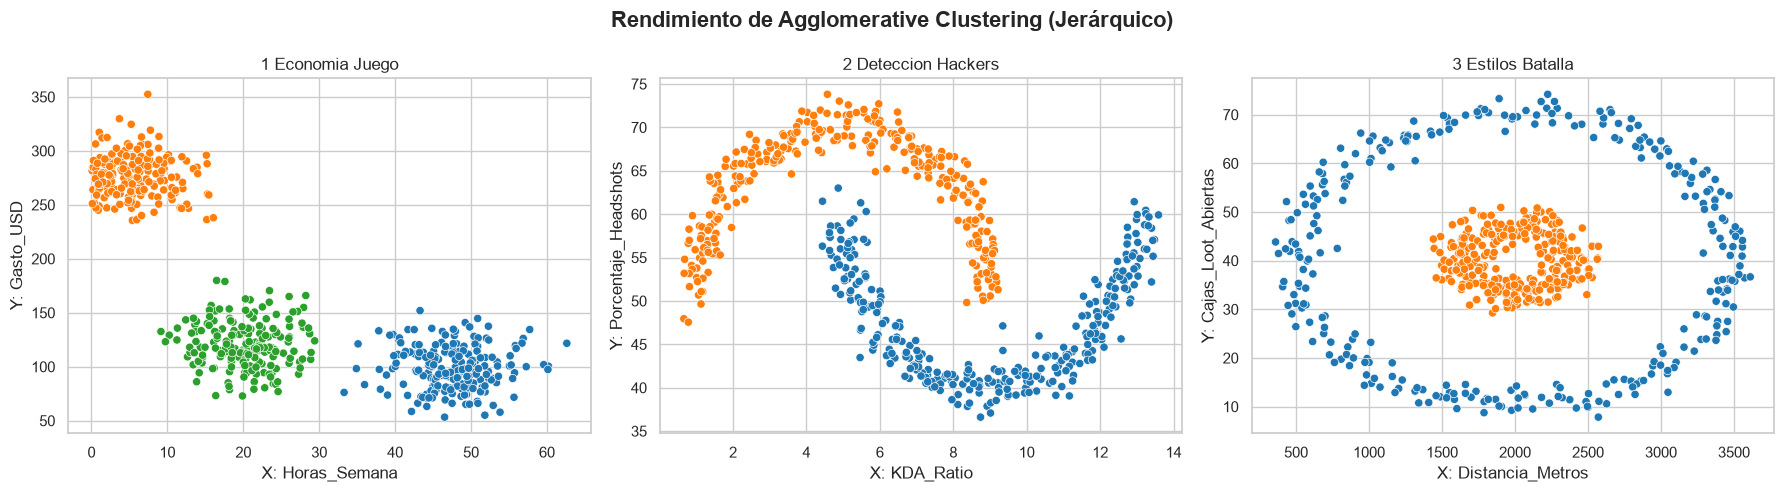

In [10]:
def config_agglomerative(k, esc):
    # Usamos 'single' linkage para demostrar cómo puede seguir formas continuas
    if 'Economia' in esc:
        return AgglomerativeClustering(n_clusters=k, linkage='ward')
    else:
        return AgglomerativeClustering(n_clusters=k, linkage='single')

evaluar_algoritmo("Agglomerative Clustering (Jerárquico)", config_agglomerative)

--- 
## 🛑 Equipo 4: Gaussian Mixture Models - GMM (Probabilístico)
**Lógica Teórica:**
En lugar de asignar fronteras duras, asume que los datos son generados por *K* campanas de Gauss (distribuciones normales) superpuestas. Calcula la *probabilidad* de que un punto pertenezca a cada campana. Permite formas elípticas.

**Predicción de Rendimiento:**
*   **Escenario 1 (Economía):** Excelente. Modela perfectamente las varianzas.
*   **Escenario 2 y 3:** Fracaso. Aunque permite óvalos, no puede curvarse para formar lunas o crear agujeros en el centro (anillos).

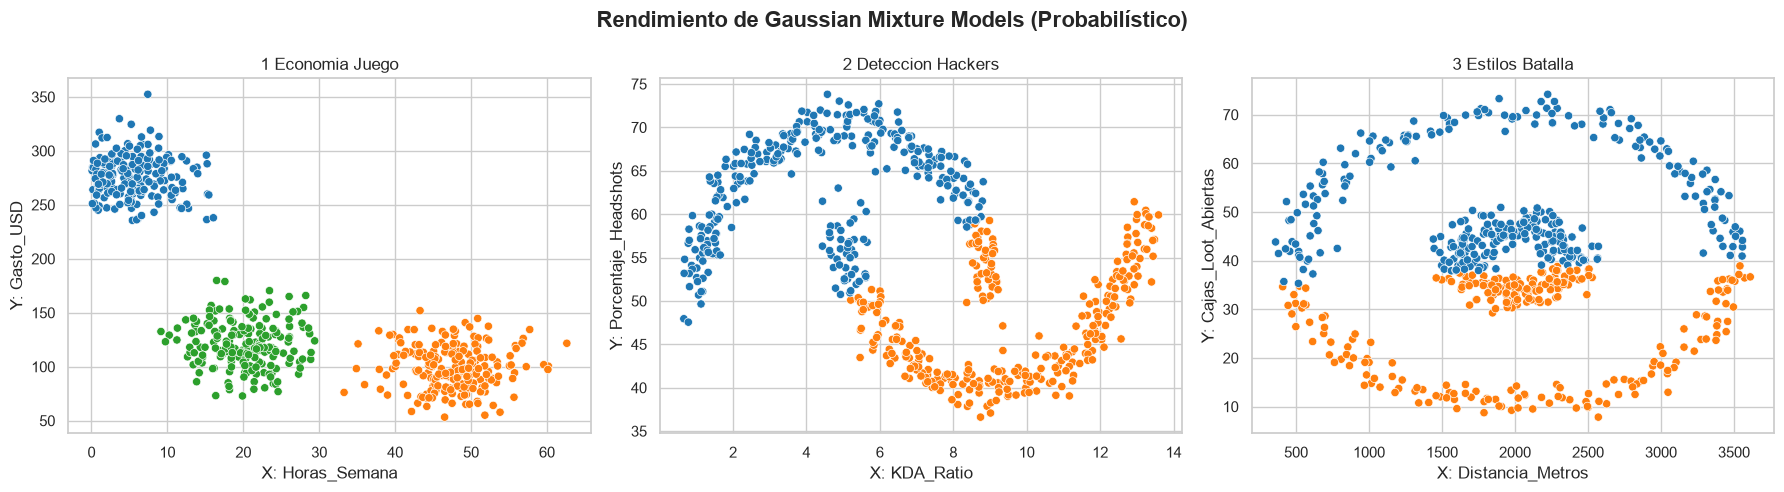

In [11]:
def config_gmm(k, esc):
    return GaussianMixture(n_components=k, covariance_type='full', random_state=42)

evaluar_algoritmo("Gaussian Mixture Models (Probabilístico)", config_gmm)

--- 
## 🛑 Equipo 5: Spectral Clustering (Basado en Grafos)
**Lógica Teórica:**
Trata los puntos de datos como nodos en un grafo conectados por puentes (distancias). Utiliza el álgebra lineal (autovalores y autovectores) de una "matriz de similitud" para proyectar los datos en una dimensión inferior donde un algoritmo sencillo como K-Means pueda cortarlos limpiamente.

**Predicción de Rendimiento:**
*   **Todos los escenarios:** Resolutor universal. Al evaluar conectividad en lugar de solo distancia bruta, puede aislar los anillos y separar las lunas perfectamente.

/home/ricglez/miniconda3/envs/mineria_datos/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/home/ricglez/miniconda3/envs/mineria_datos/lib/python3.14/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


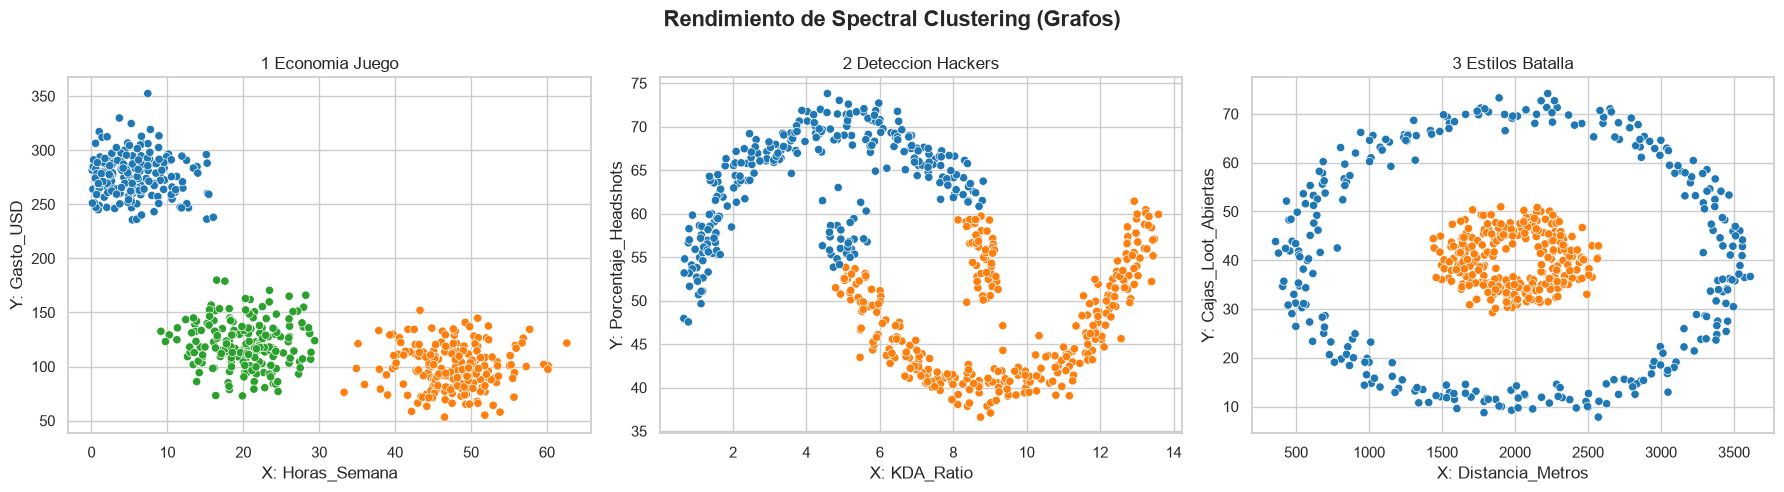

In [12]:
def config_spectral(k, esc):
    return SpectralClustering(n_clusters=k, affinity='nearest_neighbors', random_state=42)

evaluar_algoritmo("Spectral Clustering (Grafos)", config_spectral)